# When Memories Compete: How Similarity Affects Memory Retrieval in Hopfield Networks

**Blessing Ndeh** · Computational Neuroscience, Fall 2026 (PSYC 40 / COSC 16 / COGS 21) · Wednesday, November 18, 2026

---

**In short.** I stored real handwritten digits in a classical Hopfield network and asked whether it can still retrieve each memory *exactly* when the memories resemble each other. Three findings:

1. **More overlap, less retrieval.** With 3 stored images, stability falls from 100% to 0% as their mean pixel overlap rises from about 0.44 to 0.56. Noisy cues fail at slightly lower overlap.
2. **Failed memories merge, they don't swap.** All 22,599 failed retrievals ended in the same state: the pixel-by-pixel majority vote of the three images. None ended in a different stored memory.
3. **A simple rule explains it.** An image stays stable only if it differs from the other two on at least 514 of its 1,024 pixels in total. This holds under assumptions I checked for every image, and it predicts 540 of 540 cases.

*Caution:* "overlap" is raw pixel overlap, much of it shared white background. It is not how similar digits *look*.

In [1]:
# This notebook only READS saved results; it does not re-run the experiments.
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RES, FIG = Path("results"), Path("results/figures")
def show(name, width=900):
    display(Image(filename=str(FIG / name), width=width))

## 1. Objective

**Question.** Classical Hopfield theory assumes the stored memories are unrelated random patterns, but real memories share features. I wanted to know:
- How does the **similarity** between stored memories affect whether each can be retrieved exactly?
- How does the **number** of stored memories affect it?
- When retrieval fails, **where does the network go**?

**Why it matters for neuroscience.** The hippocampus is thought to keep similar experiences apart in two steps (Yassa & Stark, 2011):
- **pattern separation** in the dentate gyrus makes similar inputs less similar;
- **pattern completion** in the recurrent CA3 network fills in a memory from a partial cue.

A Hopfield network does completion only. Testing it on similar inputs shows what goes wrong when similar memories are stored *without* separation.

**How the plan changed.** I started with **5** memories per network, but almost nothing was retrieved exactly (0.3% of trials), so there was nothing to compare. A pilot with 2–4 memories showed that **3** was where outcomes varied. That became the main experiment.

## 2. Data and preprocessing

**Dataset.** *Optical Recognition of Handwritten Digits*, original 32×32 bitmaps (Alpaydin & Kaynak, 1998; UCI), file `data/optdigits-orig.cv`.
- **Format:** a 21-line header, then 946 blocks of 32 rows of `0`/`1` characters, each followed by the digit label.
- **Contents:** 946 images (85–114 per digit), about 30% ink.

**Preprocessing.**
1. **Parse and validate.** Every row must have 32 binary characters, and the counts must match the header.
2. **Convert to neurons.** White → −1, ink → +1, flattened to **N = 1,024 neurons**.
3. **Keep the more typical half of each digit** (476 images). Without this filter, the "most similar" groups were unreadable ink blobs. Results apply to this subset.
4. **Measure similarity** with the Hopfield overlap $m = \frac1N\sum_i \xi_i\eta_i$: 1 = identical, ≈0 = unrelated, −1 = inverse. A group's similarity is the mean of its pairwise overlaps.
   *A bug I caught:* 8-bit integers overflowed, giving an image overlap 0 with itself. Everything now uses 64-bit floats, with an explicit check.

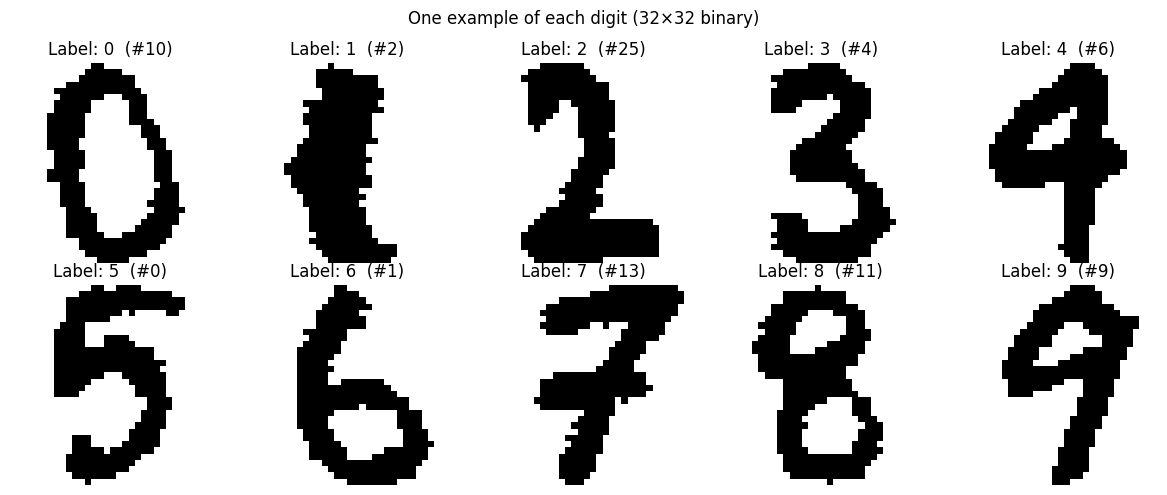

In [2]:
show("appendix/01_dataset_exploration_cell09_1.png", 700)   # one example per digit

**What overlap really measures.** It counts agreement on white pixels exactly as much as agreement on ink:

$m$ = (both white) + (both ink) − (disagree).

- **Background inflates every value.** Border pixels are almost always white, and they alone add about **0.35** to every overlap. Randomly scattered ink would give about 0.14; the observed average is 0.49.
- **Shape still sets the ranking.** Image pairs rank almost exactly as they do on shared ink alone (ρ = 0.965, right panel).

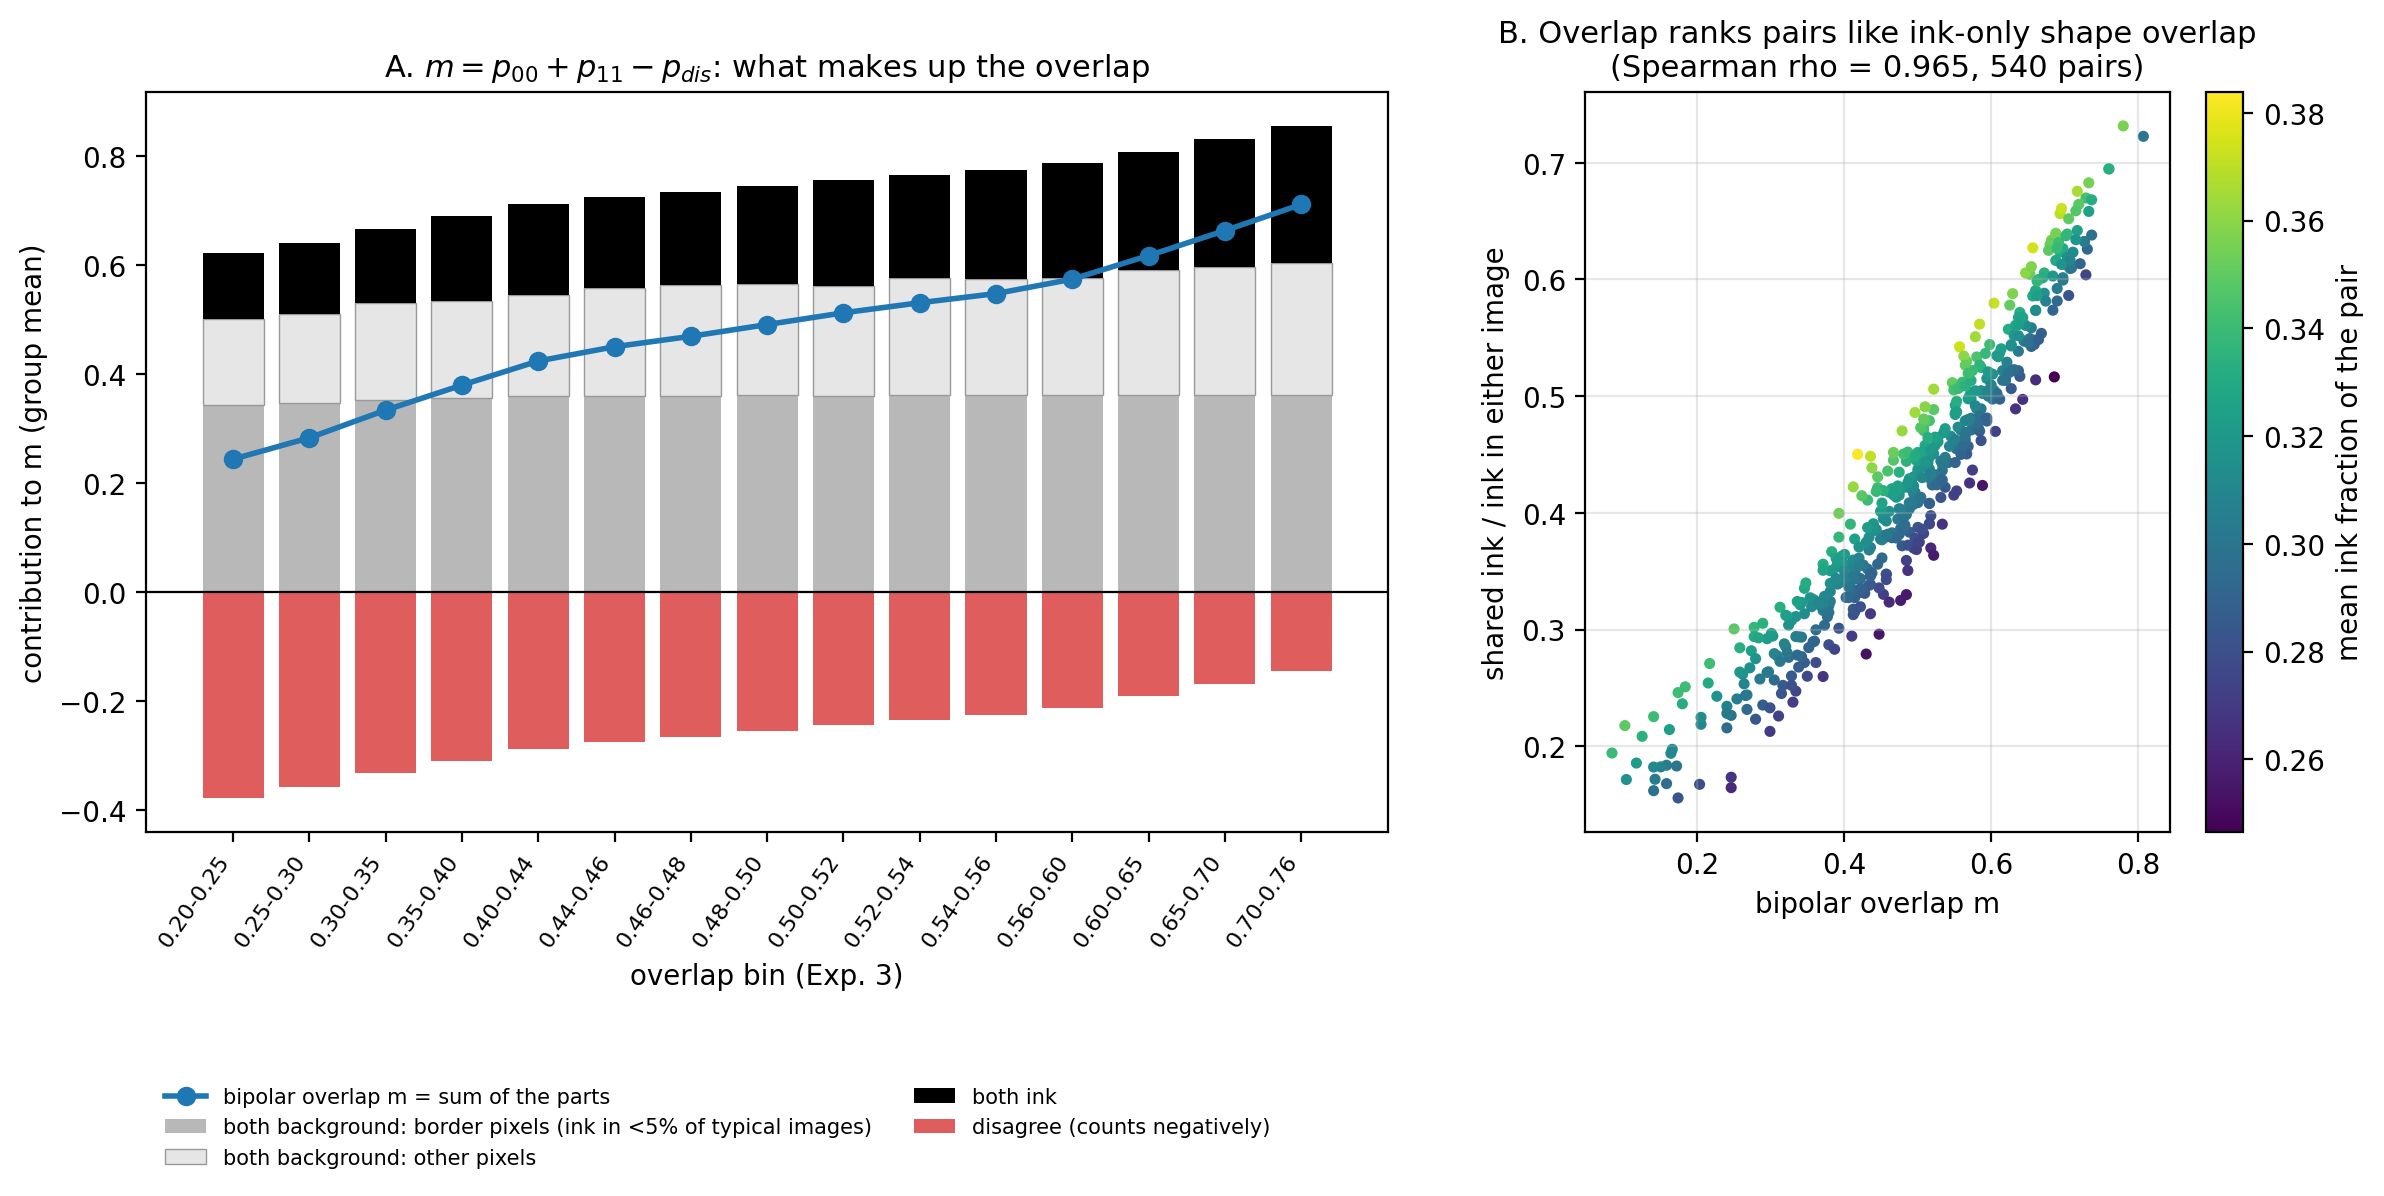

In [3]:
show("report_fig5_overlap_decomposition.png")

## 3. Model description

**The model: a classical Hopfield network** (Hopfield, 1982), with 1,024 fully connected neurons.
- **Storage (Hebbian learning):** neurons that are active together in a memory get stronger connections (Hebb, 1949). Weights are symmetric, with no self-connections.
- **Retrieval:** start from a cue, then update neurons one at a time in random order, each following the sign of its input, until nothing changes. The network rests in a stable state (an *attractor*), ideally the memory.

**Why this model.**
- It is the standard model of **content-addressable memory**: it recovers a whole memory from a degraded cue. That is the job attributed to the hippocampal CA3 network (Yassa & Stark, 2011).
- It is simple enough to **analyse exactly**, so failures can be explained, not just observed.

**What it's good at, and its weak spot.**
- It handles **unrelated** random patterns well: roughly 0.14 × N ≈ 141 of them (Amit, Gutfreund & Sompolinsky, 1985b).
- It also has unwanted stable **blends** of memories (Amit, Gutfreund & Sompolinsky, 1985a).
- Real images are related, so this tests the model outside its comfort zone.

**Implementation checks** (`src/hopfield.py`, notebook `03`), all passed:
- symmetric weights;
- a single stored image is repaired from up to 30% noise;
- energy never increases;
- 5 random patterns are all retrieved perfectly.

So later failures come from the data, not from bugs.

## 4. Metrics

| Metric | Question | How it's measured |
|---|---|---|
| **Clean stability** (primary) | Is a stored memory itself a stable state? | Start exactly at the image. Does it stay unchanged? (fraction of a group's images) |
| **Exact retrieval** (second) | Can it be recovered from a noisy cue? | Flip 5%, 10% or 20% of pixels; success only if the end state equals the original **pixel for pixel**. 20 trials per image per level. |
| **Where it ends** (descriptive) | What happens on failure? | Correct / another memory / inverted memory / other state / never settled, plus the end state's overlap with the target |

**Why exact scoring.** Failed trials still end at overlaps of 0.58–0.93 with the target. A "close enough" cut-off would count blends as successes, and the most similar groups would look *best*.

**Summaries.** The unit of analysis is the group of memories (trials are averaged within each group first). I report Spearman correlations, and a descriptive **50% point**: where a fitted S-curve crosses 50%. It was fitted only after pre-set checks that the data fall steadily and cross 50%.

## 5. Results and discussion

### 5.1 Memory load (supporting evidence)

| Experiment | Stored images | Groups | Notebook |
|---|---|---|---|
| Experiment 1 | 5 | 84 | `04` |
| Pilot | 2, 3, 4 | 12 each | `05` |
| **Experiment 2 (main)** | **3** | **180** | `06` |

- For Experiment 2, I listed all 12.9 million possible groups and drew 180 at random. The draw was spread across the overlap range, denser where outcomes change, with no image in more than 3 groups.
- **Clean stability by load:** 100% (2 images), about 51–61% (3), 6% (4), 0.5% (5).
- The groups were sampled differently, so this is context, **not** a controlled comparison.

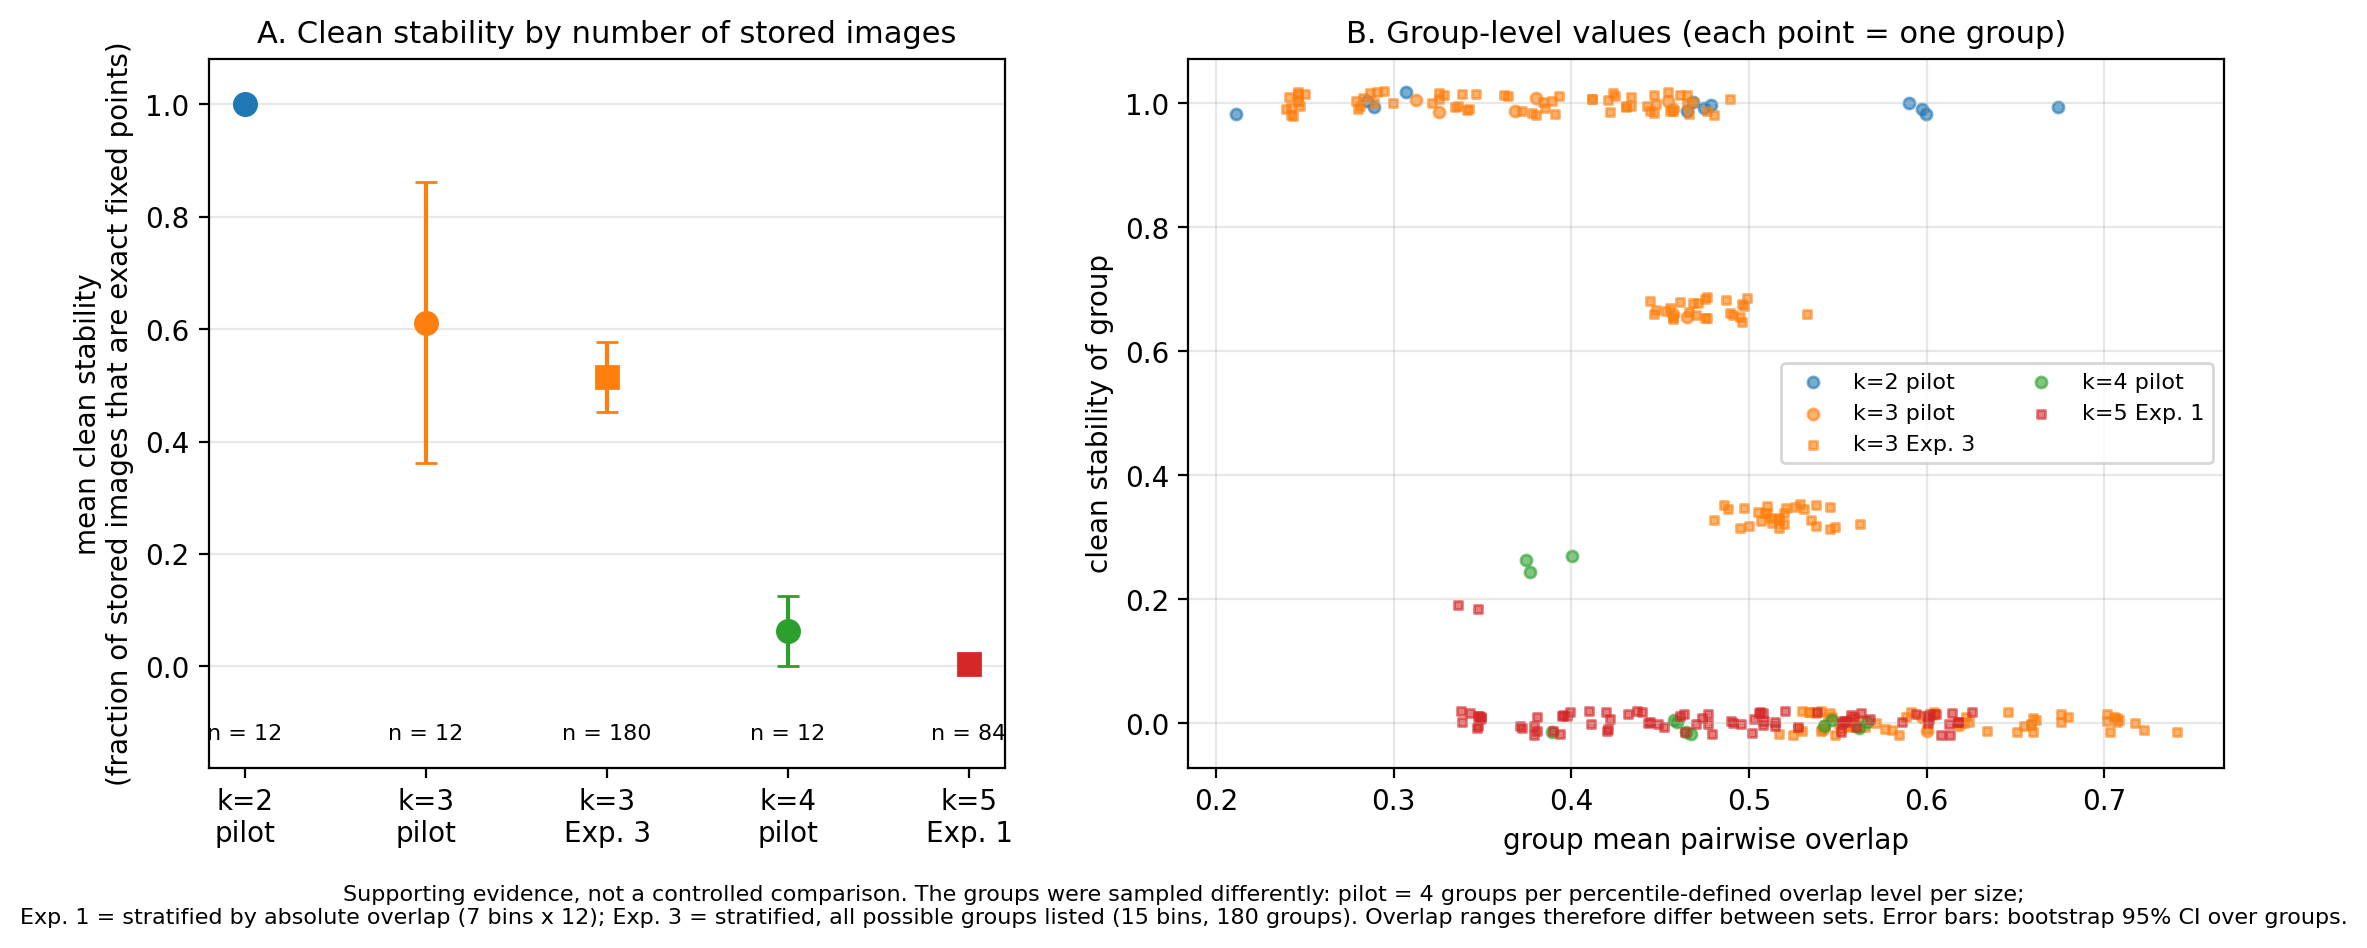

In [4]:
show("report_fig2_memory_load.png")

### 5.2 Finding 1: higher overlap, lower stability and retrieval

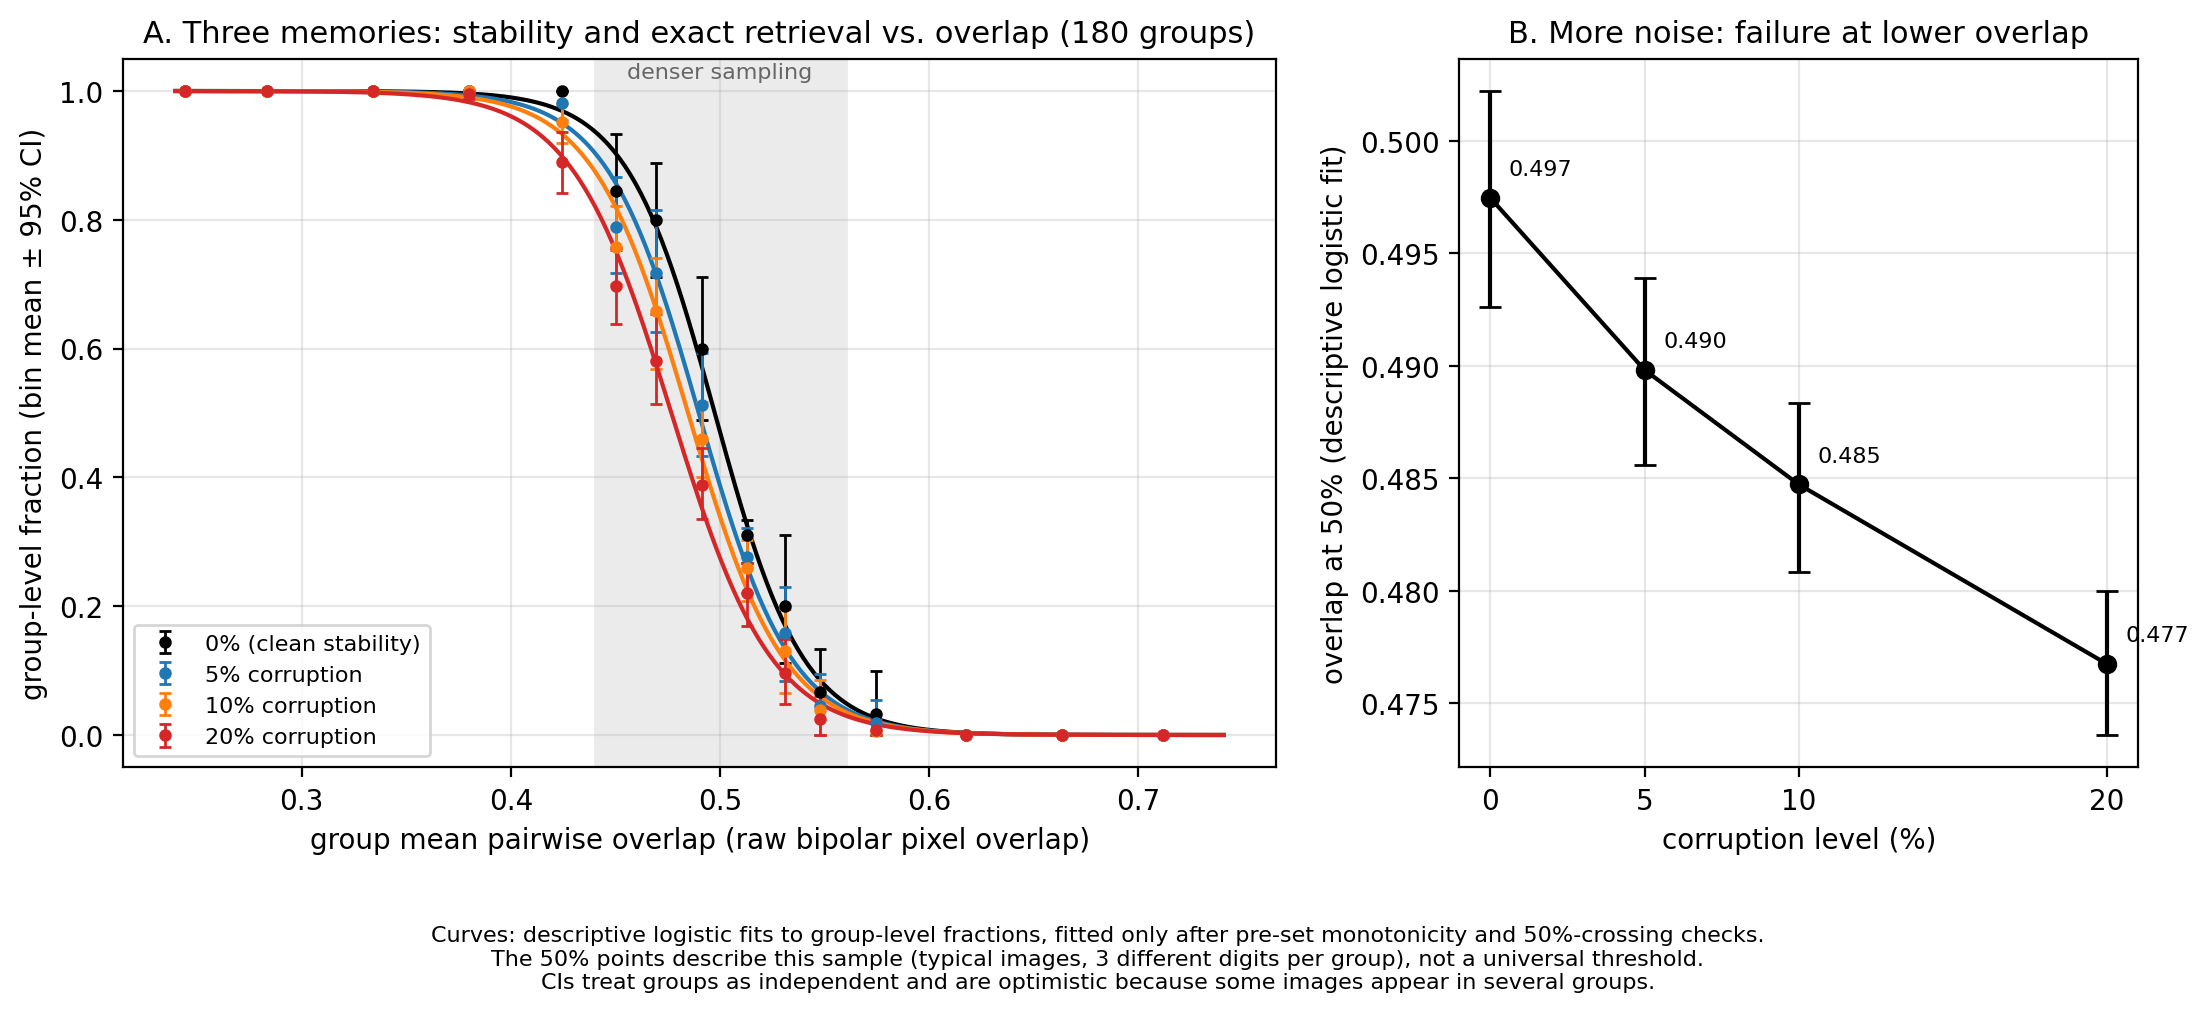

overlap bin,0.20–0.25,0.25–0.30,0.30–0.35,0.35–0.40,0.40–0.44,0.44–0.46,0.46–0.48,0.48–0.50,0.50–0.52,0.52–0.54,0.54–0.56,0.56–0.60,0.60–0.65,0.65–0.70,0.70–0.76
groups,10.0,10.0,10.0,10.00,10.00,15.00,15.00,15.00,15.00,15.00,15.00,10.00,10.0,10.0,10.0
clean stability,1.0,1.0,1.0,1.00,1.00,0.84,0.80,0.60,0.31,0.20,0.07,0.03,0.0,0.0,0.0
exact @5%,1.0,1.0,1.0,1.00,0.98,0.79,0.72,0.51,0.28,0.16,0.04,0.02,0.0,0.0,0.0
exact @10%,1.0,1.0,1.0,1.00,0.95,0.76,0.66,0.46,0.26,0.13,0.04,0.01,0.0,0.0,0.0
exact @20%,1.0,1.0,1.0,0.99,0.89,0.70,0.58,0.39,0.22,0.10,0.02,0.01,0.0,0.0,0.0


In [5]:
show("report_fig3_overlap_retrieval.png")
g = pd.read_csv(RES / "step5_group_summary.csv")
t = g.groupby("bin_label", sort=False)[["stable_frac", "acc_5", "acc_10", "acc_20"]].mean()
t.insert(0, "groups", g.groupby("bin_label", sort=False).size())
t.columns = ["groups", "clean stability", "exact @5%", "exact @10%", "exact @20%"]
t.index.name = "overlap bin"
t.round(2).T

- **By overlap:** everything is stable and retrieved below about 0.44. Stability falls from 0.84 to 0.07 between 0.44 and 0.56, and nothing is stable above 0.60.
- **Strength:** ρ = −0.93 (stability) and −0.95 to −0.96 (retrieval).
- **Robustness:** similar values with no shared images (−0.92 to −0.95) and without digit 4 (−0.91 to −0.93).
- **Noise moves the 50% point down:** 0.497 → 0.490 → 0.485 → 0.477 for 0, 5, 10 and 20% noise.

These points describe **this sample**, not a universal threshold. The relationship is an **association**: real images can't have their overlap changed independently of which digits they show.

### 5.3 Finding 2: failed memories merge into one blend

- **Where failures go:** in **22,599 of 22,599** failed trials, the end state was *exactly* the **majority vote** of the three stored images (each pixel takes the value held by at least two). I checked this pixel by pixel against the saved states.
- **Never a wrong memory:** no trial ended in a different or inverted memory.
- **Full collapse at high overlap:** above about 0.60, every cue in a group ends in that same blend.

The figure shows one real trial of each kind. The cues were recovered by replaying the saved random seeds, and every replayed end state was checked against the saved one.

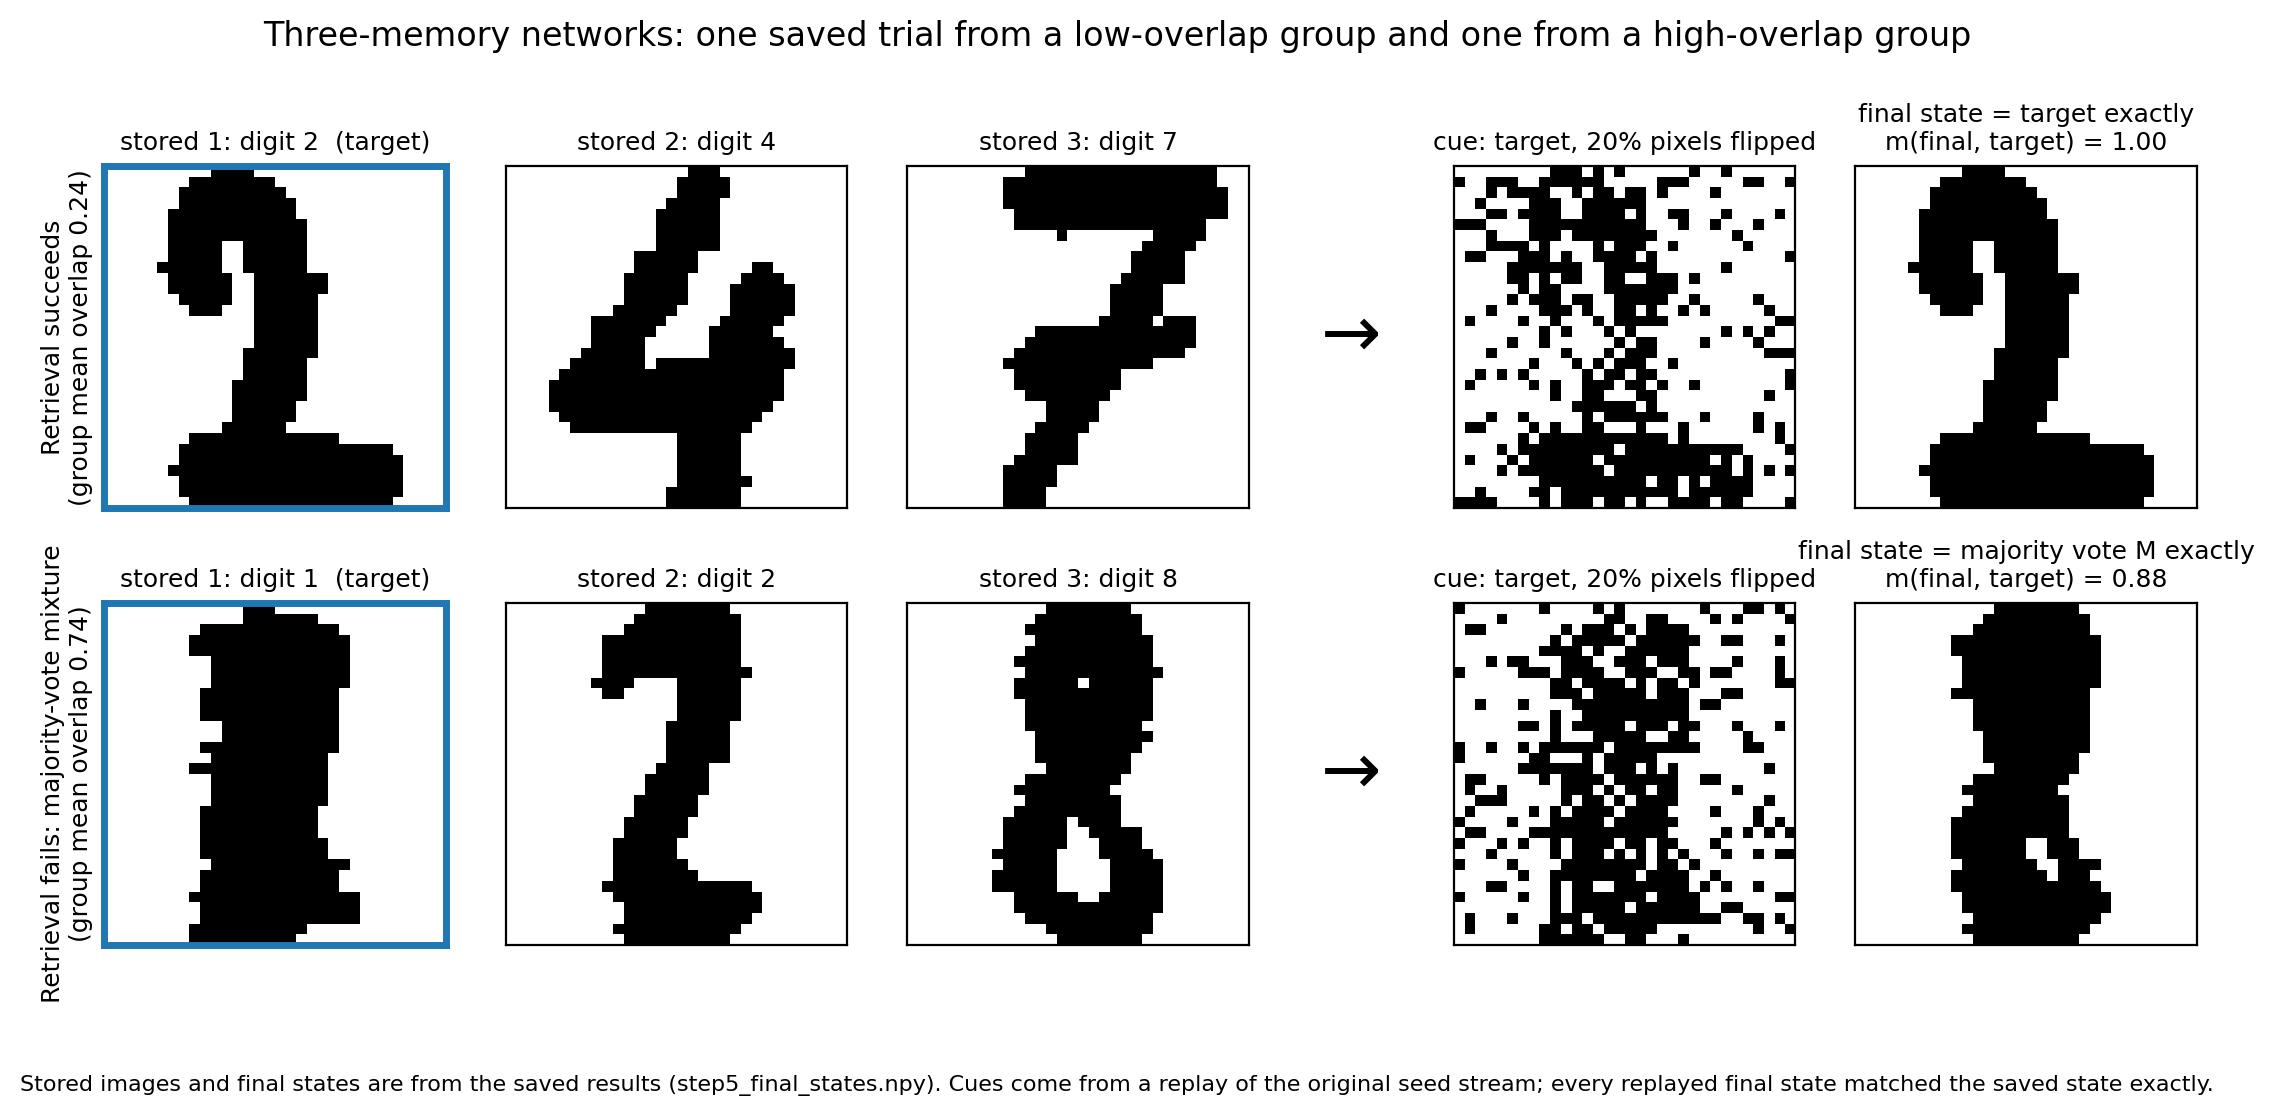

In [6]:
show("report_fig1_retrieval_examples.png")

### 5.4 Finding 3: a simple rule explains which memories survive

From the Hebbian weights, the input to every neuron can be computed exactly. The weak spots are pixels where image *a* disagrees with **both** other images: there, *a* is outvoted unless it differs enough from them overall.

$$a \text{ is stable} \iff m_{ab} + m_{ac} < 1 - \tfrac{3}{N} \iff a \text{ differs from the other two on} \ge 514 \text{ pixels in total.}$$

**This is not true for every set of three patterns.** It needs four assumptions:
1. *a* has at least one such outvoted pixel;
2. its two overlaps are not too different from each other;
3. their sum is not strongly negative;
4. *N* is even, so an input is never exactly zero.

All four hold for every one of the 540 stored images, and the rule then predicts **540 of 540** (left panel). The derivation and counterexamples are in notebook `06`, §12.

- **Why the change sits near 0.5 here:** averaged over a group's images, $m_{ab} + m_{ac}$ equals 2 × the group overlap. Images within a group differ, so the change is gradual, not a sharp step.
- **Why failures land on the blend:** I proved that an unstable image started cleanly must slide into the majority vote, which is itself stable in all 180 groups. For noisy starts this was observed every time but **not proven**.
- **Why noise matters:** barely stable images are the ones lost to noise (right panel). Margin < 0.05 gives accuracy 0.74, 0.59 and 0.43 at 5, 10 and 20% noise. That this is caused by noise is an interpretation.

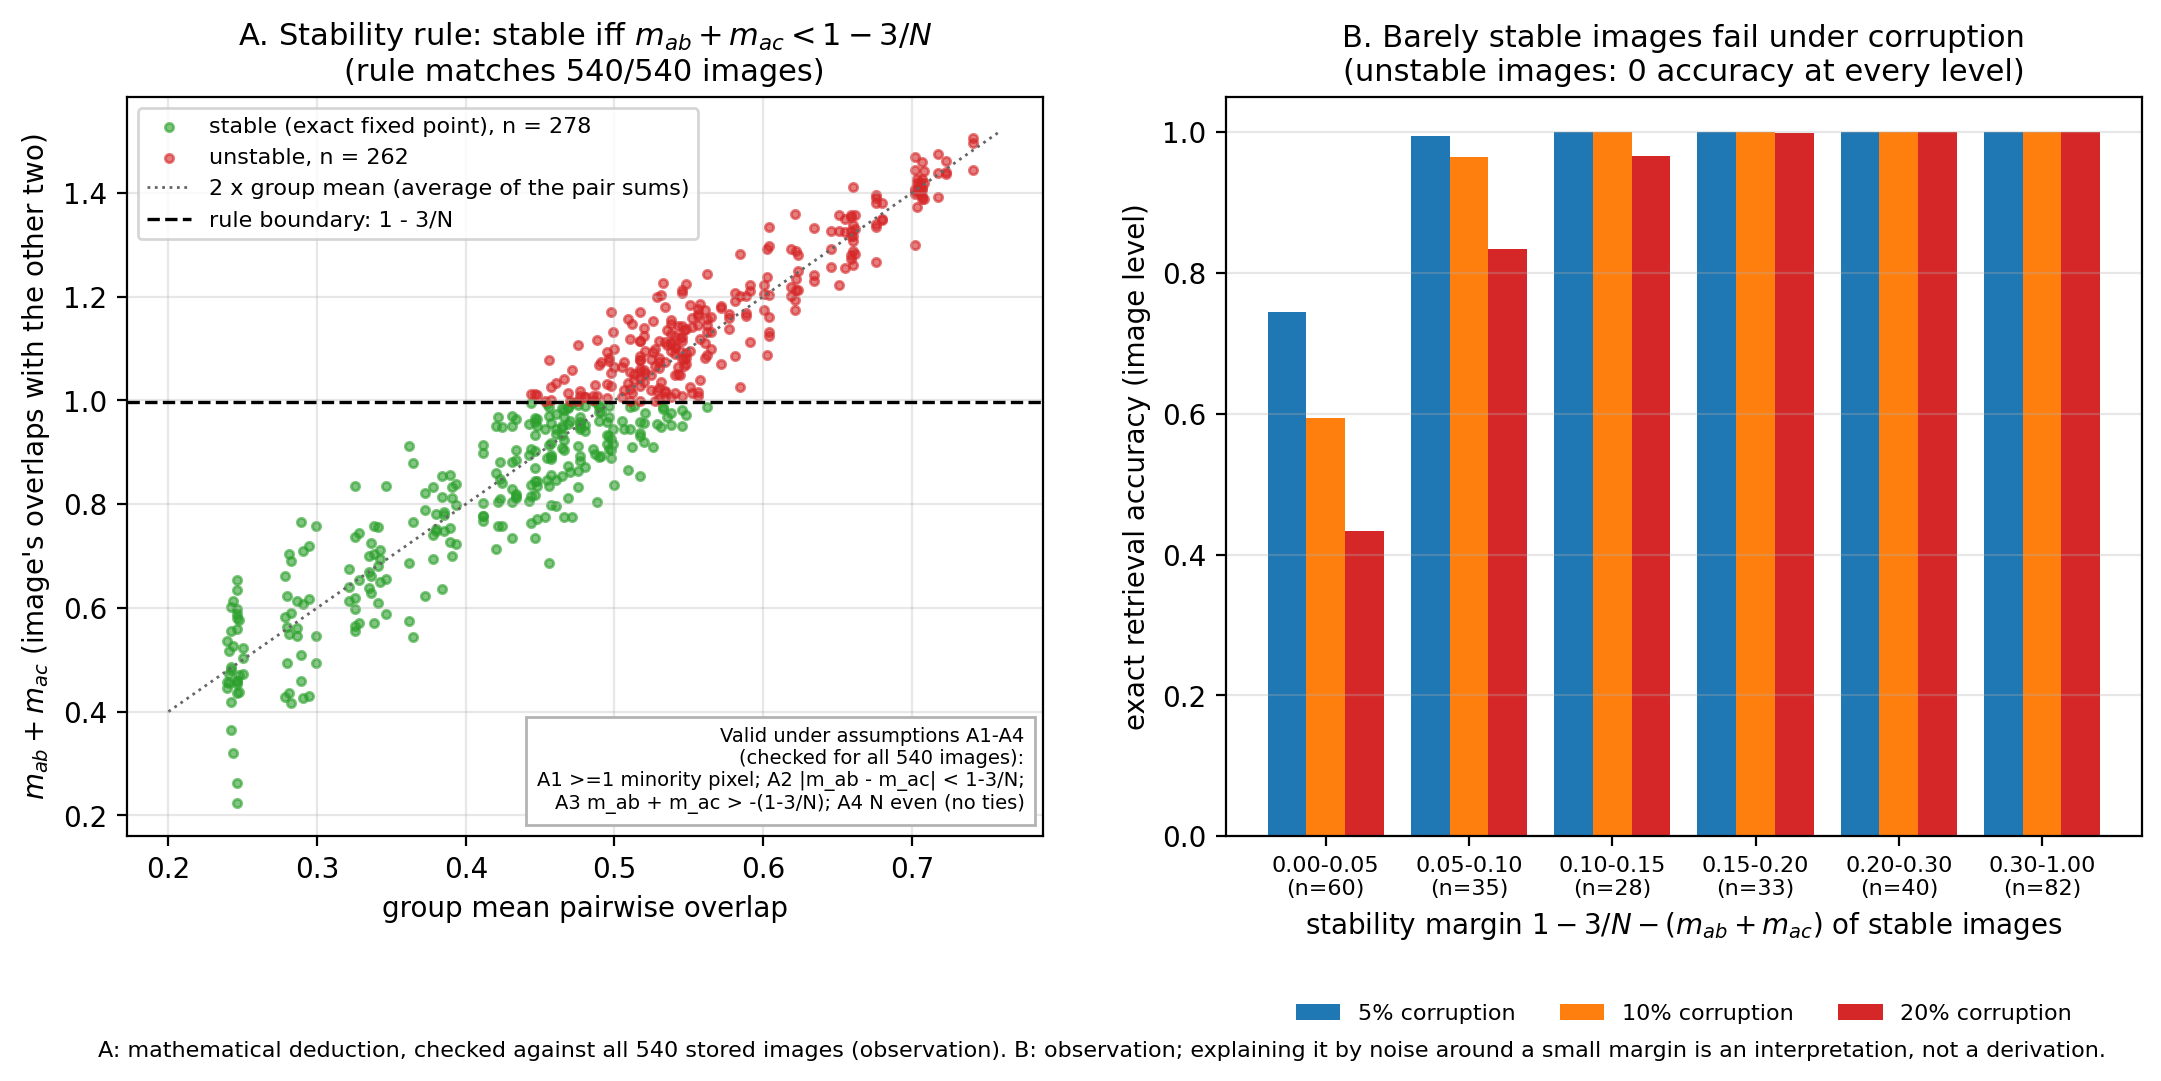

In [7]:
show("report_fig4_stability_analysis.png")

### 5.5 What this means

- **Similarity, not capacity, limits this network.** It could hold about 141 random patterns but reliably holds only 2–3 handwritten digits.
- **Interference here is merging, not substitution.** Hebbian storage is dominated by what similar memories *share*, and failing memories fall into their common blend.
- **Two kinds of failure:**
  - *storage failure*: an unstable memory can't be retrieved at all;
  - *recovery failure*: a barely stable memory is lost from a noisy cue.
- **High final overlap is not retrieval**, because the blend can look close to the target.
- **Brain connection (conceptual only):** this illustrates why a completion network benefits from first separating similar inputs, the role attributed to the dentate gyrus (Yassa & Stark, 2011; Bakker et al., 2008).
  It does **not** show that the hippocampus computes majority votes. Human studies (e.g. Reagh & Yassa, 2014; Lacy et al., 2011) use rated similarity, lure discrimination and fMRI, which can't be compared numerically with exact reconstruction. More in `reports/human_memory_comparison.md`.

### 5.6 Limitations and improvements

| Limitation | Possible improvement |
|---|---|
| Raw pixel overlap is inflated by shared background and is not perceived similarity | A coding or learning rule that discounts shared background (centred or sparse patterns) |
| Typical images only; always 3 different digits | Include atypical images and same-digit groups |
| Digit identity and overlap vary together, so only association | Synthetic patterns with directly controlled overlap |
| Some images reused across groups, so confidence intervals are optimistic | Resampling that accounts for shared images |
| Load results come from differently sampled experiments | A load experiment with one matched design |
| How 5-memory networks fail was not characterised | Save and classify the 5-memory end states |
| Classical model only (binary units, one-shot learning, no separation stage) | Add a pattern-separation stage, sparse coding or a modified learning rule |

## Repository guide

| Path | Contents |
|---|---|
| `src/` | Data loader (`optdigits.py`) and Hopfield network (`hopfield.py`) |
| `notebooks/01`–`03` | Data exploration, similarity measure, model checks |
| `notebooks/04`–`06` | Experiment 1 (5 memories), load pilot, Experiment 2 (3 memories) plus maths |
| `results/` | Saved results, configs and figures |
| `scripts/make_report_figures.py` | Rebuilds the report figures from saved results |
| `reports/` | Detailed interpretation and the human-memory comparison |

All randomness uses fixed seeds (`results/*_config.json`). Notebooks load saved results by default; set `RECOMPUTE = True` to rerun (Experiment 2 takes about 10 minutes). Setup is described in `README.md`.

## References

- Alpaydin, E., & Kaynak, C. (1998). *Optical Recognition of Handwritten Digits* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50P49
- Amit, D. J., Gutfreund, H., & Sompolinsky, H. (1985a). Spin-glass models of neural networks. *Physical Review A, 32*, 1007. https://doi.org/10.1103/PhysRevA.32.1007
- Amit, D. J., Gutfreund, H., & Sompolinsky, H. (1985b). Storing infinite numbers of patterns in a spin-glass model of neural networks. *Physical Review Letters, 55*(14), 1530–1533. https://doi.org/10.1103/PhysRevLett.55.1530
- Bakker, A., Kirwan, C. B., Miller, M., & Stark, C. E. L. (2008). Pattern separation in the human hippocampal CA3 and dentate gyrus. *Science, 319*(5870), 1640–1642. https://doi.org/10.1126/science.1152882
- Hebb, D. O. (1949). *The organization of behavior: A neuropsychological theory*. Wiley.
- Hopfield, J. J. (1982). Neural networks and physical systems with emergent collective computational abilities. *PNAS, 79*(8), 2554–2558. https://doi.org/10.1073/pnas.79.8.2554
- Lacy, J. W., Yassa, M. A., Stark, S. M., Muftuler, L. T., & Stark, C. E. L. (2011). Distinct pattern separation related transfer functions in human CA3/dentate and CA1 revealed using high-resolution fMRI and variable mnemonic similarity. *Learning & Memory, 18*(1), 15–18. https://doi.org/10.1101/lm.1971111
- Reagh, Z. M., & Yassa, M. A. (2014). Object and spatial mnemonic interference differentially engage lateral and medial entorhinal cortex in humans. *PNAS, 111*(40), E4264–E4273. https://doi.org/10.1073/pnas.1411250111
- Yassa, M. A., & Stark, C. E. L. (2011). Pattern separation in the hippocampus. *Trends in Neurosciences, 34*(10), 515–525. https://doi.org/10.1016/j.tins.2011.06.006

*Software:* Python 3.12 with NumPy, pandas, SciPy and Matplotlib (versions in `requirements.txt`).